# DC4 source catalog: standard spectral fit

**Branch: `SourceCatTest`.** The runtime COSIpy model/integration changes
are maintained on `DC4-SourceCat`; both analysis notebooks live here. This notebook contains all of its analysis functions below;
it imports no catalog, fitting or MEGAlib helper modules. The only extra model
support in COSIpy is `SpecFromFits` and the incident-energy integration fixes.

The catalog folder supplies ordinary YAML plus spectral/spatial FITS models.
Spectral tables contain just `ENERGY` and `FLUX` with units; their interpolation
rule is an ordinary `SpecFromFits.interpolation` property in the YAML. No
light curve, `.dat`, JSON recipe or `cosi-sim` checkout is read during fitting.

Default observation inputs cover **all three months**, keeping their existing
quality selection and orientation livetime, with **no additional GTI or pointing
cut**. The current default files are legacy DC4 simulations; replace them with
your matching corrected/steady-source mock when ready. Static averaged emission
does not preserve flux/pointing correlations of variable-source simulations.

Run the independent, small deterministic recovery check first, or go directly
to the full-observation section. The check is not a fit to three months of data.

In [1]:
from copy import deepcopy
from pathlib import Path
import hashlib
import json
import h5py
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import astropy.units as u
from astropy.coordinates import SkyCoord
from astropy.io import fits
from astropy.time import Time
from astromodels import Cutoff_powerlaw, Line, Model, Parameter, PointSource
from astromodels.core.model_parser import ModelParser
from histpy import Histogram, Axes, HealpixAxis
from IPython.display import display
from threeML import DataList, JointLikelihood
from threeML.exceptions.custom_exceptions import BadCovariance
from threeML.minimizer.minimization import CannotComputeCovariance, LocalMinimization

from cosipy import test_data
from cosipy.background_estimation import FreeNormBinnedBackground
from cosipy.data_io import EmCDSBinnedData
from cosipy.interfaces import ThreeMLPluginInterface
from cosipy.response import (
    FullDetectorResponse, BinnedInstrumentResponse, BinnedThreeMLModelFolding,
    BinnedThreeMLPointSourceResponse, BinnedThreeMLExtendedSourceResponse,
    ExtendedSourceResponse,
)
from cosipy.spacecraftfile import SpacecraftHistory
from cosipy.statistics import PoissonLikelihood
from cosipy.threeml.custom_functions import GalpropHealpixModel, SpecFromFits

21:18:33 WARNING   The naima package is not available. Models that depend on it will not be         ]8;id=39826;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/astromodels/functions/functions_1D/functions.py\functions.py]8;;\:]8;id=288545;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/astromodels/functions/functions_1D/functions.py#43\43]8;;\
                  available                                                                                        

WARNING   The GSL library or the pygsl wrapper cannot be loaded. Models that depend on it  ]8;id=548773;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/astromodels/functions/functions_1D/functions.py\functions.py]8;;\:]8;id=719980;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/astromodels/functions/functions_1D/functions.py#65\65]8;;\
                  will not be available.                                                                           

WARNING   The ebltable package is not available. Models that depend on it will not be     ]8;id=513085;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/astromodels/functions/functions_1D/absorption.py\absorption.py]8;;\:]8;id=410473;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/astromodels/functions/functions_1D/absorption.py#33\33]8;;\
                  available                                                                                        

21:18:34 INFO      Starting 3ML!                                                                     ]8;id=278690;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/__init__.py\__init__.py]8;;\:]8;id=785080;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/__init__.py#44\44]8;;\

WARNING   WARNINGs here are NOT errors                                                      ]8;id=564969;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/__init__.py\__init__.py]8;;\:]8;id=629197;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/__init__.py#45\45]8;;\

WARNING   but are inform you about optional packages that can be installed                  ]8;id=603392;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/__init__.py\__init__.py]8;;\:]8;id=612884;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/__init__.py#46\46]8;;\

... (2 outputs left out)

WARNING   Multinest minimizer not available                                           ]8;id=47030;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/minimizer/minimization.py\minimization.py]8;;\:]8;id=195335;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/minimizer/minimization.py#1218\1218]8;;\

WARNING   PyGMO is not available                                                      ]8;id=67608;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/minimizer/minimization.py\minimization.py]8;;\:]8;id=832086;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/minimizer/minimization.py#1228\1228]8;;\

WARNING   Could not import plugin FermiLATLike.py. Do you have the relative instrument     ]8;id=536318;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/__init__.py\__init__.py]8;;\:]8;id=343442;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/__init__.py#126\126]8;;\
                  software installed and configured?                                                               

WARNING   No fermitools installed                                              ]8;id=331288;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/utils/data_builders/fermi/lat_transient_builder.py\lat_transient_builder.py]8;;\:]8;id=479878;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/utils/data_builders/fermi/lat_transient_builder.py#44\44]8;;\

## Read the models and observation

Resolve FITS basenames from the YAML's own directory, without changing the
working directory. Native event FITS can be binned in a chosen time interval;
already time-projected histograms cannot be recut for another interval.

In [2]:
def load_source_catalog(yaml_path):
    """Load ordinary model YAML, resolving FITS paths from its own directory.

    The YAML is neither rewritten nor extended. Returned model file paths are
    absolute in memory, so later changes to the working directory are harmless.
    """
    yaml_path = Path(yaml_path).expanduser().resolve()
    contents = yaml.safe_load(yaml_path.read_text())
    if not isinstance(contents, dict) or not contents:
        raise ValueError("The catalog must be a nonempty astromodels model")

    def resolve(value):
        path = Path(value).expanduser()
        path = path if path.is_absolute() else yaml_path.parent / path
        if not path.is_file():
            raise FileNotFoundError(f"Catalog asset not found: {path}")
        return str(path.resolve())

    def relocate(node):
        if isinstance(node, dict):
            for key, value in node.items():
                if key == "_fitsfile" and value:
                    node[key] = resolve(value)
                elif key == "SpecFromFits":
                    value["fits_file"]["value"] = resolve(value["fits_file"]["value"])
                    relocate(value)
                else:
                    relocate(value)
        elif isinstance(node, list):
            for value in node:
                relocate(value)
    relocate(contents)
    return ModelParser(model_dict=contents).get_model()


def dense_counts(histogram):
    return np.asarray(histogram.to_dense(copy=False).contents, dtype=float)


def read_catalog_observation(path, *, axes=None, start=None, stop=None):
    """Read a full binned observation or bin native event FITS, optionally in time.

    Native FITS event data use the published DC4 column conventions. A projected
    HDF5 histogram cannot be given a new time cut: supply native events instead.
    The default imposes no extra time or source-pointing selection.
    """
    path = Path(path)
    if (start is None) != (stop is None) or (start is not None and stop <= start):
        raise ValueError("Supply both increasing Unix time limits, or neither")
    if not path.name.endswith((".fits", ".fits.gz")):
        if start is not None:
            raise ValueError("Use time-resolved event FITS for a new interval")
        result = Histogram.open(path).project('Em', 'Phi', 'PsiChi')
        if axes is not None and result.axes != axes:
            raise ValueError("Histogram binning/frame does not match the analysis")
        return result.to_dense(copy=False)
    if axes is None:
        raise ValueError("Supply detector axes when binning native event FITS")
    result = Histogram(axes, sparse=True)
    with fits.open(path, memmap=False) as hdul:
        events = hdul[1].data
        for offset in range(0, len(events), 250000):
            block = events[offset:offset + 250000]
            selected = np.ones(len(block), dtype=bool)
            if start is not None:
                selected = (block['TimeTags'] >= start) & (block['TimeTags'] < stop)
            if not np.any(selected):
                continue
            direction = SkyCoord(l=block['Chi galactic'][selected]*u.deg,
                                 b=block['Psi galactic'][selected]*u.deg,
                                 frame='galactic')
            result.fill(block['Energies'][selected]*u.keV,
                        block['Phi'][selected]*u.rad, direction)
    return result.to_dense(copy=False)

## Choose the fitted parameters

Use an unpolarized copy for the continuum response. NGC 4151's CPL has free
normalization, index (−5 to +5) and cutoff; its pivot is fixed at 200 keV.
Additional sources, if requested, get one shared amplitude across components.

In [3]:
def _normalizations(source):
    if isinstance(getattr(source, "spatial_shape", None), GalpropHealpixModel):
        return [source.spatial_shape.K]
    return [p for component in source.components.values()
            for name, p in component.shape.parameters.items()
            if p.is_normalization or name.split("_")[0] == "F"]


def free_source_normalization(model, source_name):
    """Free one amplitude and tie the others to it, preserving component ratios."""
    parameters = _normalizations(model.sources[source_name])
    if not parameters or parameters[0].value <= 0:
        raise ValueError(f"No positive normalization anchor for {source_name}")
    anchor = parameters[0]
    anchor.free = True
    for parameter in parameters[1:]:
        ratio = float(parameter.value / anchor.value)
        # astromodels Line is a + b*x.
        link = Line(a=0., b=ratio)
        link.a.fix = True
        link.b.fix = True
        model.link(parameter, anchor, link)
    return anchor


def unpolarized_copy(model):
    """Use total intensity with a polarization-averaged continuum response."""
    result = deepcopy(model)
    for source in result.sources.values():
        for component in source.components.values():
            if hasattr(component.polarization, 'degree'):
                component.polarization.degree.value = 0.
    return result


def replace_with_cpl(model, name='ngc4151', *, K=0.15*200.**-1.75,
                      index=-1.75, cutoff=200.):
    """Replace one point source with an independently parameterized CPL model."""
    result = unpolarized_copy(model)
    source = result.sources[name]
    if not isinstance(source, PointSource):
        raise ValueError('The example CPL target must be a point source')
    coordinate = source.position.sky_coord.galactic
    shape = Cutoff_powerlaw(K=K, piv=200., index=index, xc=cutoff)
    shape.K.bounds = (1e-10, 1e-1)
    shape.K.delta = .05*K
    shape.index.bounds = (-5., 5.)
    shape.index.delta = .05
    shape.xc.bounds = (20., 10000.)
    shape.xc.delta = 10.
    shape.piv.fix = True
    # Use physical-coordinate Minuit step sizes. Positivity still follows from
    # the explicit bounds; the default log transforms can give unreliable
    # numerical curvature for this faint CPL on top of a much larger catalog.
    shape.K.remove_transformation()
    shape.xc.remove_transformation()
    result.remove_source(name)
    result.add_source(PointSource(name, l=coordinate.l.deg, b=coordinate.b.deg,
                                  spectral_shape=shape))
    for parameter in result.parameters.values():
        parameter.fix = True
    for parameter in (shape.K, shape.index, shape.xc):
        parameter.free = True
    return result, shape

## Responses and likelihood

These are the standard COSIpy point/extended responses and Poisson likelihood,
used through threeML. All sources use the same selected spacecraft history.
The large extended detector response is cached separately from the model FITS,
keyed by the actual history and response inputs; no JSON file is produced.

In [4]:
def _hash_file(path):
    with Path(path).open('rb') as stream:
        return hashlib.file_digest(stream, 'sha256').hexdigest()


def cached_extended_response(detector_response, history, cache_directory, *,
                             orientation_path, response_path, nside_image=8,
                             nside_scatt_map=16, earth_occ=True):
    """Build/load a response for this actual history, never an unverified old GTI.

    Provenance lives inside the HDF5 response cache; no JSON sidecar is needed.
    A new cache may be large for the full DC4 response. It is kept outside the
    portable source-model folder.
    """
    history_hash = hashlib.sha256()
    for values in (history.obstime.unix, history.livetime.to_value(u.s)):
        history_hash.update(np.ascontiguousarray(values, dtype=np.float64).tobytes())
    configuration = {
        'schema': 1, 'orientation sha256': _hash_file(orientation_path),
        'response sha256': _hash_file(response_path),
        'history times and livetime sha256': history_hash.hexdigest(),
        'nside image': int(nside_image), 'nside spacecraft': int(nside_scatt_map),
        'earth occultation': bool(earth_occ),
    }
    serialized = json.dumps(configuration, sort_keys=True)
    key = hashlib.sha256(serialized.encode()).hexdigest()
    path = Path(cache_directory)/f'extended_{key[:20]}.h5'
    if path.exists():
        with h5py.File(path) as stream:
            if stream.attrs.get('static_catalog_response_key') != key:
                raise ValueError(f'Invalid response cache metadata: {path}')
        return ExtendedSourceResponse.open(path), path
    print('Generating extended response for the selected observation:', path, flush=True)
    response = detector_response.get_extended_source_response(
        history, coordsys='galactic', nside_image=nside_image,
        nside_scatt_map=nside_scatt_map, earth_occ=earth_occ,
    )
    path.parent.mkdir(parents=True, exist_ok=True)
    partial = path.with_suffix('.partial.h5')
    response.write(partial, overwrite=True)
    with h5py.File(partial, 'r+') as stream:
        stream.attrs['static_catalog_response_key'] = key
        stream.attrs['static_catalog_configuration'] = serialized
    partial.replace(path)
    return response, path

In [5]:
def make_catalog_folding(model, data, history, detector_response, extended_response):
    """Ordinary COSIpy point/extended model folding, with no temporal adapters."""
    instrument_response = BinnedInstrumentResponse(detector_response, data)
    point = BinnedThreeMLPointSourceResponse(
        data=data, instrument_response=instrument_response, sc_history=history,
        energy_axis=detector_response.axes['Ei'],
        polarization_axis=None, nside=2*data.axes['PsiChi'].nside,
    )
    if model.extended_sources and extended_response is None:
        raise ValueError('This catalog needs a matching extended response')
    extended = (BinnedThreeMLExtendedSourceResponse(data, extended_response)
                if model.extended_sources else None)
    if extended is not None and (extended_response.axes[2:] != data.axes or
                                extended_response.axes['Ei'] != detector_response.axes['Ei']):
        raise ValueError('Point/extended response and data axes differ')
    folding = BinnedThreeMLModelFolding(data, point, extended)
    folding.set_model(model)
    return folding


def make_catalog_likelihood(model, observed, background_histogram, history,
                             detector_response, extended_response, *,
                             free_source_norms=()):
    """Return a standard JointLikelihood, plugin and folding objects.

    Only the model's explicitly free source parameters and one instrumental
    background normalization are fitted. Additional catalog entries can share
    one fitted scale across their spectral components.
    """
    if observed.axes != background_histogram.axes:
        raise ValueError('Observation/background axes must match')
    for histogram in (observed, background_histogram):
        values = dense_counts(histogram)
        if np.any(~np.isfinite(values)) or np.any(values < 0):
            raise ValueError('Counts must be finite and nonnegative')
    data = EmCDSBinnedData(observed)
    for name in free_source_norms:
        free_source_normalization(model, name)
    folding = make_catalog_folding(model, data, history, detector_response, extended_response)
    background = FreeNormBinnedBackground(background_histogram, sc_history=history, copy=True)
    plugin = ThreeMLPluginInterface('catalog', PoissonLikelihood(data, folding, background),
                                    folding, background)
    live = history.cumulative_livetime().to_value(u.s)
    rate = float(dense_counts(background_histogram).sum()) / live
    if not np.isfinite(rate) or rate <= 0:
        raise ValueError('Background and live exposure must have positive totals')
    plugin.bkg_parameter['bkg_norm'] = Parameter(
        'bkg_norm', rate, min_value=0., max_value=3.*rate,
        delta=.02*rate, unit=u.Hz,
    )
    joint = JointLikelihood(model, DataList(plugin), verbose=False)
    # Standard threeML Minuit backend; use a tighter tolerance for the small
    # target contribution on top of a much larger fixed-source expectation.
    minimizer = LocalMinimization('minuit')
    minimizer.setup(ftol=1.e-3)
    joint.set_minimizer(minimizer)
    return joint, plugin, folding, background

## Minuit uncertainties and reporting

Only a validated Minuit covariance produces a pointwise 68% band using the
correlated threeML parameter samples. It is a local Gaussian approximation,
not a Bayesian posterior or a simultaneous confidence region. If bounds
truncate the samples, threeML warns and interval coverage needs separate study.

In [6]:
def fit_catalog_likelihood(joint):
    """Minuit fit with standard threeML covariance; never force a valid band."""
    try:
        joint.fit(quiet=True, compute_covariance=True)
    except (BadCovariance, CannotComputeCovariance) as exc:
        print('Covariance unavailable:', type(exc).__name__, str(exc))
        joint.fit(quiet=True, compute_covariance=False)
        joint.restore_best_fit()
        return False
    joint.restore_best_fit()
    minimum = joint._minimizer.minuit.fmin
    valid = bool(minimum.is_valid and minimum.has_accurate_covar and
                 minimum.has_posdef_covar and not minimum.has_made_posdef_covar
                 and not minimum.has_parameters_at_limit)
    if not valid:
        print('Covariance failed Minuit validation; no band will be shown.')
    return valid


def cpl_band_from_results(joint, shape, energy_keV, covariance_valid):
    """Pointwise 68% band from correlated standard threeML parameter variates."""
    energy = np.asarray(energy_keV)
    best = np.asarray(shape(energy), dtype=float)
    if not covariance_valid:
        return best, None, None
    K, index, cutoff = [np.asarray(joint.results.get_variates(p.path), dtype=float)
                         for p in (shape.K, shape.index, shape.xc)]
    draws = (K[:, None] * (energy[None, :]/shape.piv.value)**index[:, None]
             * np.exp(-energy[None, :]/cutoff[:, None]))
    lo, hi = np.quantile(draws, [.16, .84], axis=0)
    return best, lo, hi

In [7]:
repo = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p/'cosipy'/'__init__.py').is_file())
tutorial = repo/'docs/tutorials/spectral_fits/source_catalog'
DC4_ROOT = Path.home()/'Library/CloudStorage/OneDrive-ClemsonUniversity/COSI/Radio_Quiet_AGN/DC4_Files'
# Shared external model folder, used by DC4-SourceCat and SourceCatTest.
CATALOG_DIRECTORY = DC4_ROOT/'dc4_source_catalog'
CATALOG_YAML = CATALOG_DIRECTORY/'dc4_catalog.yaml'
# Keep analysis outputs and large detector-response caches OUTSIDE the model folder.
WORK = tutorial/'work'
WORK.mkdir(exist_ok=True)
catalog = load_source_catalog(CATALOG_YAML)
print(f'Loaded {len(catalog.point_sources)} point and {len(catalog.extended_sources)} extended models')

Loaded 32 point and 19 extended models


In [8]:
def report_fit(joint, plugin, folding, background, observed, shape, valid, stem, injected=None):
    # Standard threeML correlated covariance samples give marginal errors
    # and a pointwise 68% spectral band. Never show a forced covariance band.
    if valid:
        table = joint.results.get_data_frame(error_type='equal tail', cl=.68)
    else:
        table = pd.DataFrame.from_dict({
            name: dict(value=p.value, negative_error=np.nan,
                       positive_error=np.nan, error=np.nan, unit=str(p.unit))
            for name, p in joint.likelihood_model.free_parameters.items()
        }, orient='index')
        print('Covariance invalid: uncertainties and spectral band unavailable.')
    display(table)
    table.to_csv(WORK/f'{stem}_parameters.csv', index_label='parameter')

    observed_e = dense_counts(observed.project('Em'))
    source_e = dense_counts(folding.expectation().project('Em'))
    bkg_e = dense_counts(background.expectation().project('Em'))
    edges = observed.axes['Em'].edges.to_value(u.keV)
    counts = pd.DataFrame({'E_min_keV': edges[:-1], 'E_max_keV': edges[1:],
                           'observed': observed_e, 'sources': source_e,
                           'background': bkg_e, 'model': source_e+bkg_e})
    display(counts)
    counts.to_csv(WORK/f'{stem}_counts.csv', index=False)
    print(f'Log likelihood: {plugin.get_log_like():.6f}; valid covariance: {valid}')

    energy = np.geomspace(100., 10000., 400)
    # Sampling is only for standard parameter uncertainties, not fake data.
    np.random.seed(42)
    best, low, high = cpl_band_from_results(joint, shape, energy, valid)
    conversion = energy**2*u.keV.to(u.erg)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout='constrained')
    ax = axes[0]
    ax.loglog(energy/1000., conversion*best, color='tab:blue', label='Target best fit')
    if low is not None:
        ax.fill_between(energy/1000., conversion*low, conversion*high,
                        color='tab:blue', alpha=.2, label='68% covariance interval')
    if injected is not None:
        ax.loglog(energy/1000., conversion*injected(energy), 'k:', label='Injected target')
    peak = float(np.max(conversion*best))
    ax.set(xlim=(.1, 10.), ylim=(peak*1.e-6, peak*3.), xlabel='Energy (MeV)',
           ylabel=r'$E^2\,dN/dE$ (erg cm$^{-2}$ s$^{-1}$)')
    ax.legend()
    ax = axes[1]
    centers = np.sqrt(edges[:-1]*edges[1:])
    ax.errorbar(centers/1000., observed_e, yerr=np.sqrt(observed_e), fmt='o',
                markerfacecolor='white', label='Observed / expected input')
    ax.stairs(source_e+bkg_e, edges/1000., color='tab:red', label='Total model')
    ax.stairs(bkg_e, edges/1000., color='tab:green', label='Background')
    ax.set(xscale='log', yscale='log', xlabel='Measured energy (MeV)', ylabel='Counts')
    ax.legend()
    fig.savefig(WORK/f'{stem}.pdf', facecolor='white', bbox_inches='tight')
    plt.show()
    return table, counts


## Independent recovery check (small response fixture)

Use all 51 catalog entries, with NGC 4151 replaced by a known CPL. This same
CPL is injected and fitted: pivot 200 keV, index −1.75, cutoff 200 keV and
normalization `0.15 * 200**(-1.75)`. All other sources stay fixed. The fixture's
short attitude sequence is given repeated exposure solely to make this test
inexpensive. Its coarse response is not used in the observation fit below.
Counts equal their expectations (Asimov data), without a random realization.
The displayed band is a local Gaussian covariance approximation, not a
Bayesian posterior or a simultaneous confidence region. threeML warns if
physical parameter bounds truncate its covariance samples; broad or bounded
intervals require a dedicated profile/posterior analysis for inference.


  0%|          | 0/12 [00:00<?, ?it/s]

21:18:35 WARNING   We have set the min_value of Cutoff_powerlaw.K to 1e-99 because there was a     ]8;id=859869;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=430858;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#715\715]8;;\
                  postive transform                                                                                

WARNING   We have set the min_value of Cutoff_powerlaw.xc to 1e-99 because there was a    ]8;id=312092;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=87262;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#715\715]8;;\
                  postive transform                                                                                

21:18:36 INFO      set the minimizer to minuit                                             ]8;id=242543;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py\joint_likelihood.py]8;;\:]8;id=860023;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py#1017\1017]8;;\

INFO      set the minimizer to minuit                                             ]8;id=436755;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py\joint_likelihood.py]8;;\:]8;id=611250;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py#1017\1017]8;;\

21:18:53 WARNING   12.08 percent of samples have been thrown away because they failed the  ]8;id=235723;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/analysis_results.py\analysis_results.py]8;;\:]8;id=258989;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/analysis_results.py#1645\1645]8;;\
                  constraints on the parameters. This results might not be suitable for                            
                  error propagation. Enlarge the boundaries until you loose less than 1                            
                  percent of the samples.                                                                          

21:18:53 WARNING   The current value of the parameter K (1.0) was above the new maximum 0.1.       ]8;id=650846;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=268487;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#810\810]8;;\

WARNING   The current value of the parameter xc (10.0) was below the new minimum 20.0.    ]8;id=881863;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=70542;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#732\732]8;;\

,value,negative_error,positive_error,error,unit
ngc4151.spectrum.main.Cutoff_powerlaw.K,0.000014,-0.000008,0.000008,0.000008,1 / (keV s cm2)
ngc4151.spectrum.main.Cutoff_powerlaw.index,-1.750249,-0.803725,0.745433,0.774579,
ngc4151.spectrum.main.Cutoff_powerlaw.xc,200.096853,-94.346388,101.198932,97.772660,keV
bkg_norm,0.179999,-0.000155,0.000151,0.000153,Hz


,E_min_keV,E_max_keV,observed,sources,background,model
0,100.000,158.489,2.816194e+07,2.780195e+07,359998.850533,2.816195e+07
1,158.489,251.189,5.315778e+07,5.279779e+07,359998.850533,5.315778e+07
2,251.189,398.107,4.200431e+07,4.164432e+07,359998.850533,4.200432e+07
3,398.107,630.957,5.978810e+07,5.942810e+07,359998.850533,5.978810e+07
4,630.957,1000.000,6.298383e+06,5.938385e+06,359998.850533,6.298384e+06
5,1000.000,1584.890,3.879510e+06,3.519511e+06,359998.850533,3.879509e+06
6,1584.890,2511.890,2.198519e+06,1.838519e+06,359998.850533,2.198518e+06
7,2511.890,3981.070,5.648919e+05,2.048919e+05,359998.850533,5.648907e+05
8,3981.070,6309.570,3.934887e+05,3.348873e+04,359998.850533,3.934876e+05
9,6309.570,10000.000,3.616139e+05,1.613931e+03,359998.850533,3.616128e+05


Log likelihood: 2173951651.467498; valid covariance: True


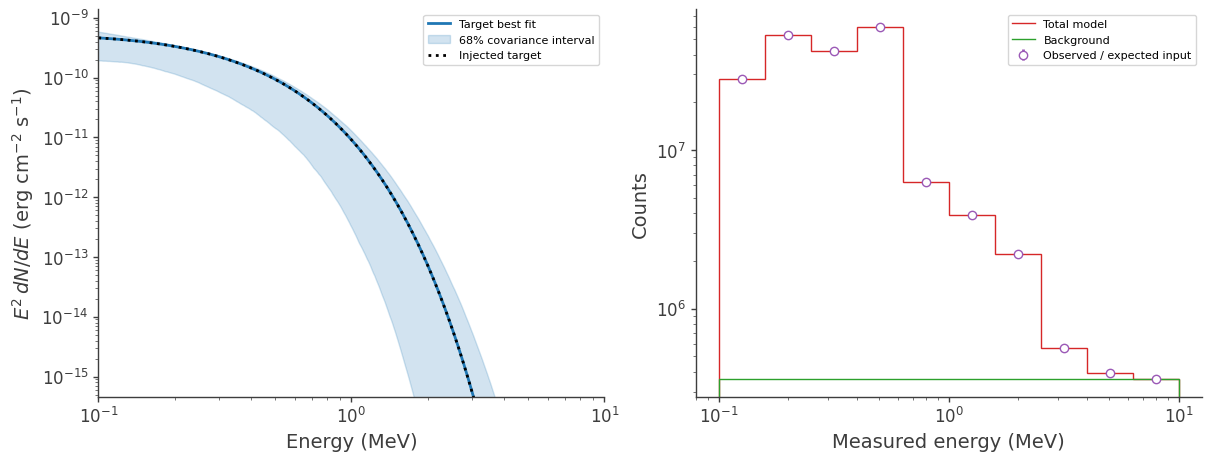

Injected CPL and instrumental background recovered: PASS


In [9]:
from astromodels import Cutoff_powerlaw

base = SpacecraftHistory.open(test_data.path/'20280301_2s.fits')
regression_history = SpacecraftHistory(
    base.obstime, base.attitude, base.location, livetime=base.livetime*1.e7,
)
regression_response = FullDetectorResponse.open(test_data.path/'test_full_detector_response.h5')
regression_extended = regression_response.get_extended_source_response(
    regression_history, nside_image=1, nside_scatt_map=2,
)
regression_axes = regression_extended.axes[2:]
regression_model, regression_shape = replace_with_cpl(catalog)
regression_folding = make_catalog_folding(
    regression_model, EmCDSBinnedData(Histogram(regression_axes)),
    regression_history, regression_response, regression_extended,
)
regression_background_hist = Histogram(
    regression_axes, contents=np.full(regression_axes.shape, 1000.),
)
regression_observed = regression_folding.expectation()+regression_background_hist
regression_injected = Cutoff_powerlaw(K=.15*200.**-1.75, piv=200., index=-1.75, xc=200.)

# Deliberately start away from the injected values.
regression_shape.K.value *= 1.1
regression_shape.index.value = -1.5
regression_shape.xc.value = 250.
regression_joint, regression_plugin, regression_folding, regression_background = make_catalog_likelihood(
    regression_model, regression_observed, regression_background_hist,
    regression_history, regression_response, regression_extended,
)
np.random.seed(42)  # Reproducible covariance draws.
regression_covariance_valid = fit_catalog_likelihood(regression_joint)
regression_parameters, regression_counts = report_fit(
    regression_joint, regression_plugin, regression_folding, regression_background,
    regression_observed, regression_shape, regression_covariance_valid,
    'static_catalog_recovery', injected=regression_injected,
)
assert np.isclose(regression_shape.K.value, .15*200.**-1.75, rtol=.01)
assert np.isclose(regression_shape.index.value, -1.75, atol=.01)
assert np.isclose(regression_shape.xc.value, 200., rtol=.01)
expected_rate = dense_counts(regression_background_hist).sum()/regression_history.cumulative_livetime().to_value(u.s)
assert np.isclose(regression_plugin.bkg_parameter['bkg_norm'].value, expected_rate, rtol=.001)
print('Injected CPL and instrumental background recovered: PASS')


## Full three-month observation fit

Configure the full observation/background files below. No preselected NGC 4151
histograms are used. Existing SAA/quality filtering and the orientation's live
exposure are retained. The catalog's fixed averages are not renormalized for a
new interval. This first fit uses three free CPL parameters plus one overall
instrumental-background rate. Optionally free one shared amplitude per additional
catalog source; multi-component ratios are tied.

**First response build:** the full NSIDE-8 extended response can occupy roughly
14 GB and take substantial time. Its cache is separate from the compact model
bundle. The cache key includes input-file hashes, selected history/livetime and
response settings. A pre-existing target-cut response is never silently reused.


In [ ]:
OBSERVATION = DC4_ROOT/'Mock_Data/dc4_mock_dataset_3months_binned_data_filtered_with_SAAcut_time_ordered.hdf5'
BACKGROUND = DC4_ROOT/'Background/Total_DC4_BG_3months_binned_data_filtered_with_SAAcut_withSAAbck.hdf5'
ORIENTATION = DC4_ROOT/'DC4_final_530km_3_month_with_slew_15sbins_GalacticEarth_SAA.ori'
RESPONSE = DC4_ROOT/'ResponseContinuum.o3.e100_10000.b10log.s10396905069491.m2284.filtered.nonsparse.binnedimaging.imagingresponse.h5'

TARGET = 'ngc4151'
FREE_OTHER_NORMALIZATIONS = []  # Example: ['crab']; one amplitude across all its components.
TIME_RANGE = None              # Default: complete observation, no new GTI.
# For a flare: (Unix_start, Unix_stop), and BOTH input files must be native event
# FITS covering that range, with the same quality cuts. Refitting a mean source
# here is a starting analysis; replace its shape for an interval-specific model.


In [ ]:
history = SpacecraftHistory.open(ORIENTATION)
detector_response = FullDetectorResponse.open(RESPONSE)
# For native event FITS, supply the detector binning in Galactic coordinates.
# For binned HDF5 this also validates that the supplied dataset is compatible.
detector_axes = Axes([
    detector_response.axes['Em'], detector_response.axes['Phi'],
    HealpixAxis(nside=detector_response.axes['PsiChi'].nside,
                coordsys='galactic', label='PsiChi'),
])
if TIME_RANGE is not None:
    # Never recut a time-projected histogram for a different interval.
    start, stop = TIME_RANGE
    history = history.select_interval(Time(start, format='unix'), Time(stop, format='unix'))
    data_hist = read_catalog_observation(OBSERVATION, axes=detector_axes, start=start, stop=stop)
    background_hist = read_catalog_observation(BACKGROUND, axes=data_hist.axes, start=start, stop=stop)
else:
    data_hist = read_catalog_observation(OBSERVATION, axes=detector_axes)
    background_hist = read_catalog_observation(BACKGROUND, axes=data_hist.axes)
extended_response, response_cache = cached_extended_response(
    detector_response, history, WORK/'response_cache', orientation_path=ORIENTATION,
    response_path=RESPONSE, nside_image=8,
    nside_scatt_map=2*data_hist.axes['PsiChi'].nside,
)
print(f'History: {history.tstart.isot} to {history.tstop.isot}; live {history.cumulative_livetime()}')
print(f'Total observed counts: {dense_counts(data_hist).sum():,.0f}')
print('Extended response:', response_cache)


In [ ]:
# Freeze the other catalog shapes. Replace the target's averaged tabulation
# with the CPL to be estimated; its injected tail is not fitted in this example.
model, shape = replace_with_cpl(catalog, TARGET)
joint, plugin, folding, background = make_catalog_likelihood(
    model, data_hist, background_hist, history, detector_response, extended_response,
    free_source_norms=FREE_OTHER_NORMALIZATIONS,
)
print('Free parameters:', list(joint.likelihood_model.free_parameters))
covariance_valid = fit_catalog_likelihood(joint)
parameters, counts = report_fit(
    joint, plugin, folding, background, data_hist, shape, covariance_valid,
    'dc4_full_observation_catalog_fit',
)


### Flare or other interval analyses

Choose an interval using the native event inputs, apply the identical time
interval to source/background events and the spacecraft history, and construct
the matching response. The histogram reader rejects time cuts on HDF5 input.
There is only one entry for each combined AGN; replace that entry's average
spectrum and refit the interval's normalization and shape. No separate quiet
state remains to double-count. `replace_with_cpl(catalog, TARGET)` illustrates
replacement for a point target; another spectral function can be substituted
using ordinary astromodels. The finite/repeating light curves are not consulted
at fitting time. A short flare spectrum cannot generally be predicted from
its full-observation mean alone.
